In [94]:
import time
from itertools import combinations

import pandas as pd
import matplotlib.pyplot as plt

In [95]:
def load_transactions(path):
    transactions = []
    with open(path, encoding="cp1251") as f:
        for line in f:
            items = {item.strip() for item in line.split(",") if item.strip()}
            if items:
                transactions.append(items)
    return transactions

In [96]:
transactions = load_transactions("baskets.csv")

all_items = set.union(*transactions)
lengths = [len(t) for t in transactions]

print("Транзакций:", len(transactions))
print("Уникальных товаров:", len(all_items))
print("Длина транзакции: мин", min(lengths), "макс", max(lengths),"средняя", round(sum(lengths) / len(lengths), 2))
print("Пример:", transactions[1])

Транзакций: 7501
Уникальных товаров: 115
Длина транзакции: мин 1 макс 20 средняя 3.91
Пример: {'гамбургер', 'фрикадельки', 'яйца'}


In [97]:
def build_tidsets(transactions):
    tidsets = {}
    for tid, transaction in enumerate(transactions):
        for item in transaction:
            tidsets.setdefault(item, set()).add(tid)
    return tidsets

In [98]:
def find_L1(tidsets, n, min_support):
    L1 = {}
    for item, tids in tidsets.items():
        if len(tids) / n >= min_support:
            L1[(item,)] = tids
    return L1

In [99]:
n = len(transactions)
tidsets = build_tidsets(transactions)

print("Номера транзакций с яйцами:", sorted(tidsets["яйца"])[:5])
print()

for s in [0.01, 0.03, 0.05, 0.10, 0.15]:
    print(f"порог {s:.0%}: частых товаров {len(find_L1(tidsets, n, s))}")
print()

L1 = find_L1(tidsets, n, 0.05)
top = sorted(L1.items(), key=lambda kv: len(kv[1]), reverse=True)[:5]
for itemset, tids in top:
    print(itemset, len(tids), f"{len(tids) / n:.2%}")

Номера транзакций с яйцами: [1, 10, 12, 17, 18]

порог 1%: частых товаров 74
порог 3%: частых товаров 36
порог 5%: частых товаров 25
порог 10%: частых товаров 7
порог 15%: частых товаров 5

('минеральная вода',) 1788 23.84%
('макароны',) 1410 18.80%
('яйца',) 1348 17.97%
('картофель-фри',) 1282 17.09%
('шоколад',) 1229 16.38%


In [100]:
def has_infrequent_subset(candidate, L_prev):
    for subset in combinations(candidate, len(candidate) - 1):
        if subset not in L_prev:
            return True
    return False

In [101]:
def generate_candidates(L_prev):
    prev_itemsets = sorted(L_prev)
    candidates = {}

    for i in range(len(prev_itemsets)):
        a = prev_itemsets[i]
        for j in range(i + 1, len(prev_itemsets)):
            b = prev_itemsets[j]

            if a[:-1] != b[:-1]:
                break

            candidate = a + (b[-1],)

            if has_infrequent_subset(candidate, L_prev):
                continue

            candidates[candidate] = L_prev[a] & L_prev[b]

    return candidates

In [102]:
L1 = find_L1(tidsets, n, 0.05)
C2 = generate_candidates(L1)
L2 = {c: t for c, t in C2.items() if len(t) / n >= 0.05}
C3 = generate_candidates(L2)

print("L1:", len(L1), " C2:", len(C2), " L2:", len(L2), " C3:", len(C3))
for c, tids in L2.items():
    print(c, f"{len(tids) / n:.2%}")

L1: 25  C2: 300  L2: 3  C3: 0
('макароны', 'минеральная вода') 6.12%
('минеральная вода', 'шоколад') 5.27%
('минеральная вода', 'яйца') 5.09%


In [103]:
def filter_by_support(candidates, n, min_support):
    return {c: tids for c, tids in candidates.items()
            if len(tids) / n >= min_support}

In [104]:
def apriori(transactions, min_support, order="support"):
    #order=lex лексиграфическая сортировка, order=support – по убыванию поддержки
    if order not in ("support", "lex"):
        raise ValueError("order должен быть 'support' или 'lex'")

    n = len(transactions)
    tidsets = build_tidsets(transactions)

    frequent = {}
    L = find_L1(tidsets, n, min_support)

    while L:
        for itemset, tids in L.items():
            frequent[itemset] = len(tids)
        C = generate_candidates(L)
        L = filter_by_support(C, n, min_support)

    if order == "support":
        key = lambda kv: (-kv[1], kv[0])
    else:
        key = lambda kv: kv[0]

    rows = [(itemset, len(itemset), count, count / n)
            for itemset, count in sorted(frequent.items(), key=key)]

    return pd.DataFrame(rows, columns=["itemset", "length", "count", "support"])

In [105]:
result = apriori(transactions, 0.005, order="support")

print("Всего частых наборов:", len(result))
print(result["length"].value_counts().sort_index())
result.head(10)

Всего частых наборов: 738
length
1     97
2    454
3    186
4      1
Name: count, dtype: int64


,itemset,length,count,support
0,"(минеральная вода,)",1,1788,0.238368
1,"(макароны,)",1,1410,0.187975
2,"(яйца,)",1,1348,0.179709
3,"(картофель-фри,)",1,1282,0.170911
4,"(шоколад,)",1,1229,0.163845
5,"(зеленый чай,)",1,991,0.132116
6,"(молоко,)",1,972,0.129583
7,"(говяжий фарш,)",1,737,0.098254
8,"(замороженные овощи,)",1,715,0.095321
9,"(блинчики,)",1,713,0.095054


In [106]:
result[result["length"] == 2].head(5)

,itemset,length,count,support
21,"(макароны, минеральная вода)",2,459,0.061192
23,"(минеральная вода, шоколад)",2,395,0.052660
26,"(минеральная вода, яйца)",2,382,0.050927
29,"(минеральная вода, молоко)",2,360,0.047994
34,"(говяжий фарш, минеральная вода)",2,307,0.040928


In [107]:
apriori(transactions, 0.03, order="lex").head(10)

,itemset,length,count,support
0,"(авокадо,)",1,250,0.033329
1,"(блинчики,)",1,713,0.095054
2,"(блинчики, минеральная вода)",2,253,0.033729
3,"(гамбургер,)",1,654,0.087188
4,"(говяжий фарш,)",1,737,0.098254
5,"(говяжий фарш, макароны)",2,302,0.040261
6,"(говяжий фарш, минеральная вода)",2,307,0.040928
7,"(замороженные овощи,)",1,715,0.095321
8,"(замороженные овощи, минеральная вода)",2,268,0.035729
9,"(замороженный смузи,)",1,475,0.063325


In [108]:
def run_experiment(transactions, min_support, repeats=5):
    times = []
    for _ in range(repeats):
        start = time.perf_counter()
        result = apriori(transactions, min_support)
        times.append(time.perf_counter() - start)

    row = {
        "min_support": min_support,
        "time_best": min(times),
        "time_mean": sum(times) / len(times),
        "total": len(result),
    }
    counts = result["length"].value_counts()
    for length in sorted(counts.index):
        row[f"len{length}"] = counts[length]
    return row

In [109]:
thresholds = [0.005, 0.01, 0.02, 0.03, 0.05, 0.10, 0.15]

experiments = pd.DataFrame([run_experiment(transactions, s) for s in thresholds])

len_cols = sorted([c for c in experiments.columns if c.startswith("len")])
experiments[len_cols] = experiments[len_cols].fillna(0).astype(int)
experiments = experiments[["min_support", "time_best", "time_mean", "total"] + len_cols]

experiments

,min_support,time_best,time_mean,total,len1,len2,len3,len4
0,0.005,0.046326,0.048115,738,97,454,186,1
1,0.010,0.027454,0.027742,261,74,170,17,0
2,0.020,0.017857,0.018217,104,54,50,0,0
3,0.030,0.013131,0.013240,55,36,19,0,0
4,0.050,0.010448,0.010569,28,25,3,0,0
5,0.100,0.006314,0.006431,7,7,0,0,0
6,0.150,0.006246,0.007172,5,5,0,0,0


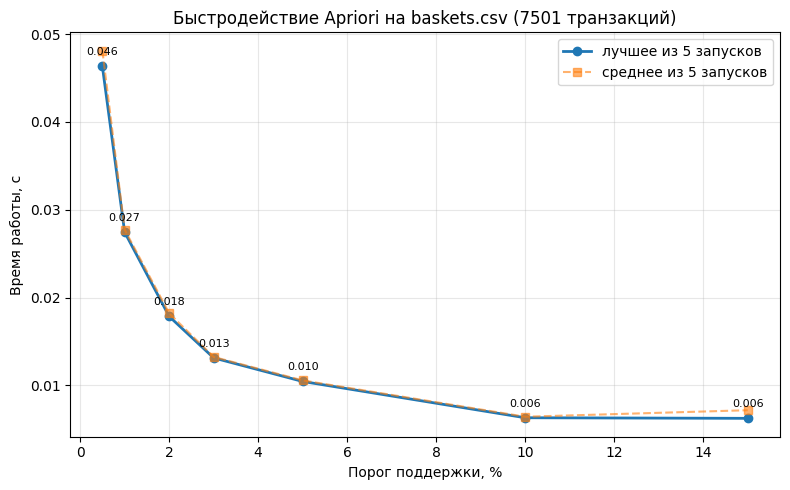

In [110]:
x = experiments["min_support"] * 100

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(x, experiments["time_best"], marker="o", linewidth=2,
        label="лучшее из 5 запусков")
ax.plot(x, experiments["time_mean"], marker="s", linestyle="--", alpha=0.6,
        label="среднее из 5 запусков")

for xi, yi in zip(x, experiments["time_best"]):
    ax.annotate(f"{yi:.3f}", (xi, yi), textcoords="offset points",
                xytext=(0, 8), ha="center", fontsize=8)

ax.set_xlabel("Порог поддержки, %")
ax.set_ylabel("Время работы, с")
ax.set_title(f"Быстродействие Apriori на baskets.csv ({n} транзакций)")
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()
fig.savefig("time_vs_support.png", dpi=150, bbox_inches="tight")

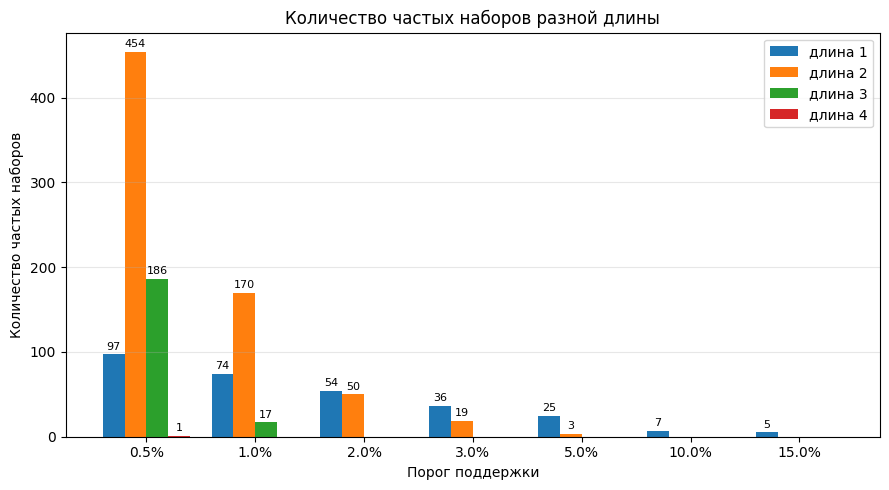

In [111]:
lengths = [int(c[3:]) for c in len_cols]
width = 0.8 / len(lengths)
positions = range(len(experiments))

fig, ax = plt.subplots(figsize=(9, 5))

for k, col in zip(lengths, len_cols):
    offset = (k - 1 - (len(lengths) - 1) / 2) * width
    bars = ax.bar([p + offset for p in positions], experiments[col],
                  width, label=f"длина {k}")
    ax.bar_label(bars, labels=[str(v) if v else "" for v in experiments[col]],
                 fontsize=8, padding=2)

ax.set_xticks(list(positions))
ax.set_xticklabels([f"{s:.1%}" for s in experiments["min_support"]])
ax.set_xlabel("Порог поддержки")
ax.set_ylabel("Количество частых наборов")
ax.set_title("Количество частых наборов разной длины")
ax.legend()
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
fig.savefig("counts_by_length.png", dpi=150, bbox_inches="tight")